# ASL Predictor - Drive se model load karo, image do, jawab lo
Is notebook mein training nahi hoti. Ye sirf aap ka **trained model Google Drive se load** karta hai aur aap ki **image par prediction** deta hai.

**Kaise chalana hai:** (GPU zaroori nahi, CPU bhi theek hai)
1. Cell 1 chalao (Drive allow karna parega).
2. Cell 2 chalao: model load hoga, aur likha aayega kaun si file use hui.
3. Cell 4 chalao: "Choose Files" se image upload karo, prediction dikhegi.

## 1. Google Drive mount aur settings
Agar aap ka folder kisi aur jagah hai to sirf `MODEL_DIR` badlo.

In [1]:
import os, json
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from google.colab import drive, files

drive.mount("/content/drive")

MODEL_DIR = "/content/drive/MyDrive/asl_output"   # <- apna folder (jisme labels.json aur model files hain)
LOW_CONFIDENCE = 0.60                              # is se kam confidence par warning dikhegi

assert os.path.isdir(MODEL_DIR), f"Folder nahi mila: {MODEL_DIR}"
print("Folder mein ye files hain:", sorted(os.listdir(MODEL_DIR)))

Mounted at /content/drive
Folder mein ye files hain: ['.ipynb_checkpoints', 'asl_model.tflite', 'best_phase1.keras', 'best_phase2.keras', 'classification_report.txt', 'confusion_matrix.png', 'labels.json', 'saved_model', 'training_curves.png']


## 2. Model aur labels load karo
Pehle `asl_model.keras`, na mile to `best_phase2.keras` (wohi best fine-tuned weights), phir `saved_model/` try hota hai.

In [2]:
# ---- labels.json (class ke naam aur unka order) ----
labels_path = os.path.join(MODEL_DIR, "labels.json")
assert os.path.exists(labels_path), "labels.json nahi mili - ye zaroori hai (class order isi mein hai)"
with open(labels_path) as f:
    meta = json.load(f)
class_names = meta["class_names"]
IMG_SIZE = tuple(meta.get("img_size", [160, 160]))
print(f"{len(class_names)} classes: {class_names}")

# ---- model load (3 tareeqe, pehla jo chale) ----
model, tfsm, source = None, None, None

for fname in ["asl_model.keras", "best_phase2.keras"]:
    p = os.path.join(MODEL_DIR, fname)
    if os.path.exists(p):
        try:
            model = keras.models.load_model(p, compile=False)
            source = fname
            break
        except Exception as e:
            print(f"{fname} load nahi hui:", str(e)[:200])

if model is None:
    sm_dir = os.path.join(MODEL_DIR, "saved_model")
    if os.path.isdir(sm_dir):
        tfsm = keras.layers.TFSMLayer(sm_dir, call_endpoint="serving_default")
        source = "saved_model/"

assert source is not None, "Koi bhi model file load nahi hui. Upar ki file list check karo."

if model is not None:
    IMG_SIZE = tuple(model.input_shape[1:3])
    assert model.output_shape[-1] == len(class_names), "Model ke classes aur labels.json match nahi karte"

print(f"\nModel load ho gaya: {source}")
print("Input size:", IMG_SIZE, "| Classes:", len(class_names))

29 classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']

Model load ho gaya: best_phase2.keras
Input size: (160, 160) | Classes: 29


## 3. Prediction ke functions
Image ko bilkul wesay resize kiya jata hai jaise training mein hua tha (bilinear, pixels 0-255, normalize nahi karna). Phone ki ghumi hui photos (EXIF rotation) bhi theek hoti hain.

In [3]:
def preprocess(path):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img).convert("RGB")
    arr = np.array(img, dtype=np.float32)                              # 0-255
    arr = tf.image.resize(arr, IMG_SIZE, method="bilinear").numpy()    # training jaisa resize
    return arr

def predict_probs(arr):
    batch = arr[None].astype(np.float32)
    if model is not None:
        out = model(batch, training=False)
    else:
        out = tfsm(tf.constant(batch))
        if isinstance(out, dict):
            out = list(out.values())[0]
    return np.array(out)[0]

def predict_and_show(path, top_k=5):
    arr = preprocess(path)
    probs = predict_probs(arr)
    idx = np.argsort(probs)[::-1][:top_k]
    best, conf = class_names[idx[0]], float(probs[idx[0]])

    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
    ax[0].imshow(arr.astype("uint8")); ax[0].axis("off")
    ax[0].set_title(os.path.basename(path), fontsize=10)
    names = [class_names[i] for i in idx][::-1]
    vals = [float(probs[i]) * 100 for i in idx][::-1]
    colors = ["#2a7de1" if n == best else "#9db8d9" for n in names]
    ax[1].barh(names, vals, color=colors)
    ax[1].set_xlim(0, 100); ax[1].set_xlabel("Confidence (%)")
    ax[1].set_title(f"Prediction: {best}  ({conf:.1%})", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

    if best == "nothing":
        print("Note: model ko image mein koi haath nahi mila ('nothing').")
    if conf < LOW_CONFIDENCE:
        print(f"Warning: confidence {conf:.0%} kam hai. Saaf roshni, simple background aur haath beech mein rakh kar dobara try karo.")
    return best, conf

print("Functions ready")

Functions ready


## 4. Image upload karo aur prediction lo
Cell chalane par **Choose Files** aayega. Ek ya kai images select karo (jpg/png/webp). Prediction har image ke liye alag dikhegi.

Saving images (6).jfif to images (6).jfif


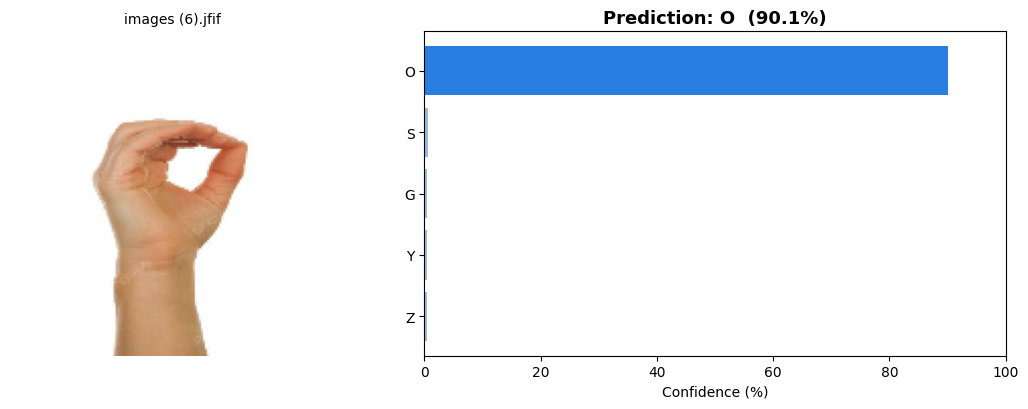

==> images (6).jfif: O (90.1%)



In [9]:
uploaded = files.upload()

for name in uploaded.keys():
    path = os.path.join("/content", name)
    try:
        best, conf = predict_and_show(path)
        print(f"==> {name}: {best} ({conf:.1%})\n")
    except Exception as e:
        print(f"{name} par prediction nahi ho saki:", e)

## 5. (Optional) Drive ya Colab ki kisi image ka path dekar prediction
Agar image pehle se Drive mein hai to upload ki zaroorat nahi. Path badal kar chalao.

In [ ]:
IMAGE_PATH = "/content/drive/MyDrive/test_image.jpg"   # <- apni image ka path likho

if os.path.exists(IMAGE_PATH):
    predict_and_show(IMAGE_PATH)
else:
    print("Ye path nahi mila, sahi path likho:", IMAGE_PATH)